# Data Preprocessing


## Importing libraries


In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "jax")  # Keras 3 runs on JAX, TensorFlow or PyTorch

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, precision_recall_fscore_support
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import keras
from keras import models
from keras import layers
import warnings
warnings.simplefilter(action='ignore')
sns.set()
plt.style.use("ggplot")
%matplotlib inline


## Importing the dataset

In [2]:
data = pd.read_csv('data/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')

data

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,1.0,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,0.0,0.0,6.0,4.0,1.0
70688,1.0,0.0,1.0,1.0,29.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,2.0,0.0,0.0,1.0,1.0,10.0,3.0,6.0
70689,1.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,15.0,0.0,1.0,0.0,13.0,6.0,4.0
70690,1.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0


In [3]:
X = data.iloc[:, 1:]
y = data.iloc[:, 0]

In [4]:
X

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,4.0,0.0,0.0,0.0,0.0,6.0,4.0,1.0
70688,0.0,1.0,1.0,29.0,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,1.0,1.0,10.0,3.0,6.0
70689,1.0,1.0,1.0,25.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,5.0,15.0,0.0,1.0,0.0,13.0,6.0,4.0
70690,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0


In [5]:
y

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
70687    1.0
70688    1.0
70689    1.0
70690    1.0
70691    1.0
Name: Diabetes_binary, Length: 70692, dtype: float64

## Data Exploration

0 is for no diabetes or only during pregnancy, 1 is for prediabetes/diabetes

In [6]:
value_counts = y.value_counts()*100/len(y)
value_counts

Diabetes_binary
0.0    50.0
1.0    50.0
Name: count, dtype: float64

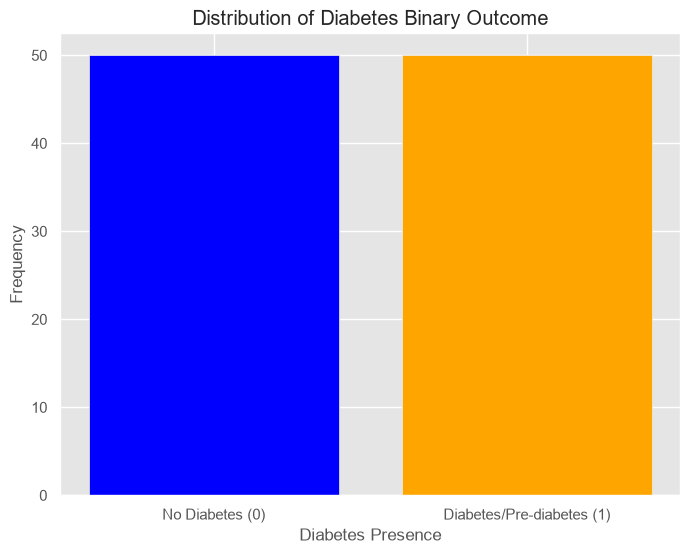

In [7]:
plt.figure(figsize=(8, 6))
plt.bar(value_counts.index.astype(str), value_counts.values, color=['blue', 'orange'])
plt.title('Distribution of Diabetes Binary Outcome')
plt.xlabel('Diabetes Presence')
plt.ylabel('Frequency')
plt.xticks(ticks=[0, 1], labels=['No Diabetes (0)', 'Diabetes/Pre-diabetes (1)'])
plt.show()

In [8]:
X.columns

Index(['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
       'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')

We try to identify whether each feature in the dataset has any outliers based on the Interquartile Range (IQR) method:

In [9]:
for feature in X:
    Q1 = X[feature].quantile(0.25)
    Q3 = X[feature].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR
    if X[(X[feature]>upper)].any(axis=None):
        print(feature, "yes")
    else:
        print(feature, "no")

HighBP no
HighChol no
CholCheck no
BMI yes
Smoker no
Stroke yes
HeartDiseaseorAttack yes
PhysActivity no
Fruits no
Veggies no
HvyAlcoholConsump yes
AnyHealthcare no
NoDocbcCost yes
GenHlth no
MentHlth yes
PhysHlth yes
DiffWalk no
Sex no
Age no
Education no
Income no


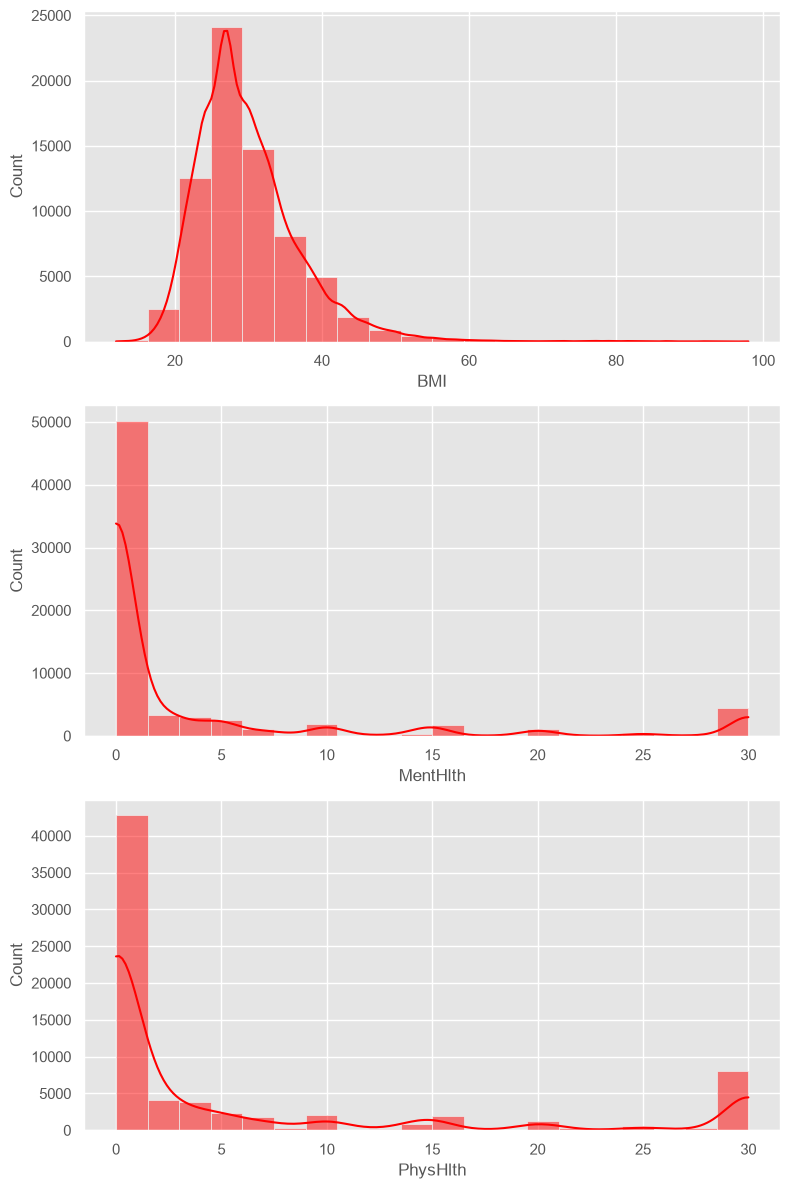

In [10]:
fig,ax = plt.subplots(3,1, figsize=(8,12))
sns.histplot(X.BMI, bins=20, kde=True, ax=ax[0], color="red")
sns.histplot(X.MentHlth, bins=20, kde=True, ax=ax[1], color="red")
sns.histplot(X.PhysHlth, bins=20, kde=True, ax=ax[2], color="red")
plt.tight_layout()
plt.show()

In [11]:
# Checking for missing values
missing_values = data.isnull().sum()

# Summarizing the distribution of the data
data_description = data.describe(include='all')

missing_values, data_description


(Diabetes_binary         0
 HighBP                  0
 HighChol                0
 CholCheck               0
 BMI                     0
 Smoker                  0
 Stroke                  0
 HeartDiseaseorAttack    0
 PhysActivity            0
 Fruits                  0
 Veggies                 0
 HvyAlcoholConsump       0
 AnyHealthcare           0
 NoDocbcCost             0
 GenHlth                 0
 MentHlth                0
 PhysHlth                0
 DiffWalk                0
 Sex                     0
 Age                     0
 Education               0
 Income                  0
 dtype: int64,
        Diabetes_binary        HighBP      HighChol     CholCheck  \
 count     70692.000000  70692.000000  70692.000000  70692.000000   
 mean          0.500000      0.563458      0.525703      0.975259   
 std           0.500004      0.495960      0.499342      0.155336   
 min           0.000000      0.000000      0.000000      0.000000   
 25%           0.000000      0.000000      0.0

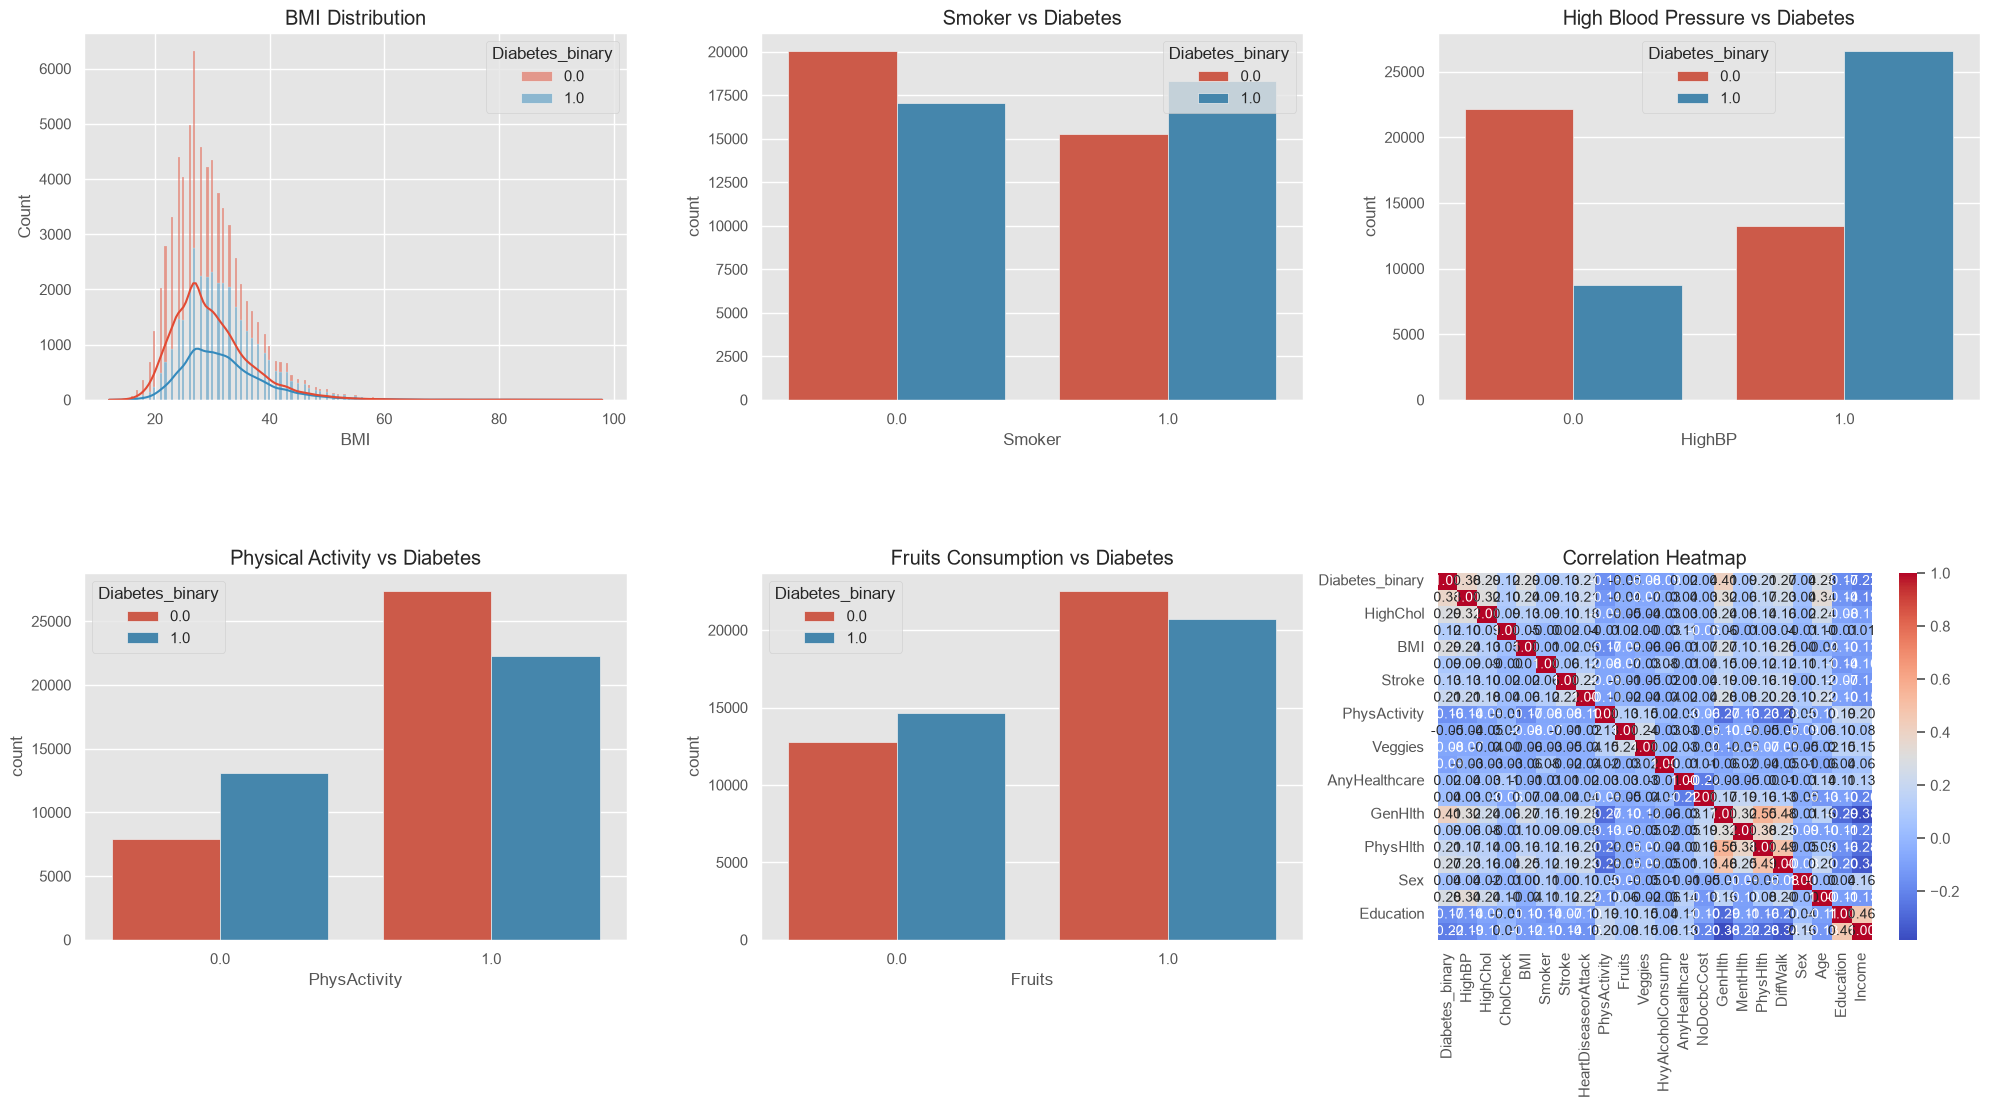

In [12]:

# Setting up the visualizations
plt.figure(figsize=(20, 15))

# Histogram for BMI
plt.subplot(3, 3, 1)
sns.histplot(data=data, x='BMI', kde=True, hue='Diabetes_binary', multiple='stack')
plt.title('BMI Distribution')

# Bar plot for Smoker
plt.subplot(3, 3, 2)
sns.countplot(data=data, x='Smoker', hue='Diabetes_binary')
plt.title('Smoker vs Diabetes')

# Bar plot for HighBP
plt.subplot(3, 3, 3)
sns.countplot(data=data, x='HighBP', hue='Diabetes_binary')
plt.title('High Blood Pressure vs Diabetes')

# Bar plot for PhysActivity
plt.subplot(3, 3, 4)
sns.countplot(data=data, x='PhysActivity', hue='Diabetes_binary')
plt.title('Physical Activity vs Diabetes')

# Bar plot for Fruits
plt.subplot(3, 3, 5)
sns.countplot(data=data, x='Fruits', hue='Diabetes_binary')
plt.title('Fruits Consumption vs Diabetes')

# Correlation heatmap
plt.subplot(3, 3, 6)
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()


## Splitting the dataset into the Training set and Test set

In [13]:
X = X.drop(columns = ["AnyHealthcare","NoDocbcCost", "Income", "Education"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [14]:
X_train

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age
7295,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,1.0,0.0,0.0,0.0,9.0
44106,1.0,1.0,1.0,36.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,4.0,10.0,0.0,1.0,1.0,7.0
50743,1.0,1.0,1.0,27.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,5.0,25.0,30.0,1.0,1.0,9.0
29129,0.0,1.0,1.0,29.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,9.0
63691,1.0,0.0,1.0,32.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,3.0,1.0,2.0,0.0,1.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49100,1.0,1.0,1.0,31.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,2.0,1.0,30.0,0.0,1.0,11.0
20609,1.0,1.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,3.0,10.0,0.0,0.0,10.0
21440,0.0,0.0,1.0,19.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,5.0,0.0,0.0,0.0,4.0
50057,1.0,1.0,1.0,39.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,3.0,1.0,1.0,10.0


In [15]:
y_train

7295     0.0
44106    1.0
50743    1.0
29129    0.0
63691    1.0
        ... 
49100    1.0
20609    0.0
21440    0.0
50057    1.0
5192     0.0
Name: Diabetes_binary, Length: 49484, dtype: float64

## Feature Scaling

In [16]:
non_binary_features = [col for col in X_train.columns if X_train[col].nunique() > 2]

print(non_binary_features)



['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age']


No Fitting on Test Data: Always fit the scaler on the training data only. This ensures the model is only exposed to information from the training set.

In [17]:
scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)  # fit on training data only
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)       # reuse the training min/max
y_train.reset_index(drop=True, inplace=True)
y_test.reset_index(drop=True, inplace=True)

In [18]:
X_train

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age
0,0.0,0.0,1.0,0.139535,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.25,0.033333,0.000000,0.0,0.0,0.666667
1,1.0,1.0,1.0,0.279070,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.75,0.333333,0.000000,1.0,1.0,0.500000
2,1.0,1.0,1.0,0.174419,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.00,0.833333,1.000000,1.0,1.0,0.666667
3,0.0,1.0,1.0,0.197674,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.25,0.000000,0.000000,0.0,0.0,0.666667
4,1.0,0.0,1.0,0.232558,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.50,0.033333,0.066667,0.0,1.0,0.583333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49479,1.0,1.0,1.0,0.220930,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.25,0.033333,1.000000,0.0,1.0,0.833333
49480,1.0,1.0,1.0,0.174419,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.25,0.100000,0.333333,0.0,0.0,0.750000
49481,0.0,0.0,1.0,0.081395,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.25,0.166667,0.000000,0.0,0.0,0.250000
49482,1.0,1.0,1.0,0.313953,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.00,0.000000,0.100000,1.0,1.0,0.750000


In [19]:
y_test

0        0.0
1        1.0
2        0.0
3        0.0
4        1.0
        ... 
21203    1.0
21204    0.0
21205    0.0
21206    0.0
21207    1.0
Name: Diabetes_binary, Length: 21208, dtype: float64

# Function to evaluate metrics

In [20]:
all_metrics ={}
def evaluate_metrics(model_name, yt, yp):
    results_pos = {}
    results_pos['accuracy'] = accuracy_score(yt, yp)
    precision, recall, f1_score, _ = precision_recall_fscore_support(yt, yp, average='binary')
    results_pos['recall'] = recall
    results_pos['precision'] = precision
    results_pos['f1score'] = f1_score
    all_metrics[model_name] = results_pos
    return results_pos

# Unsupervised Learning: K-means Clustering

## The elbow method

In [21]:
wcss = []
for i in range(1, 11):
  kmeans = KMeans(n_clusters = i, init='k-means++', random_state= 42)
  kmeans.fit(X_train)
  wcss.append(kmeans.inertia_)

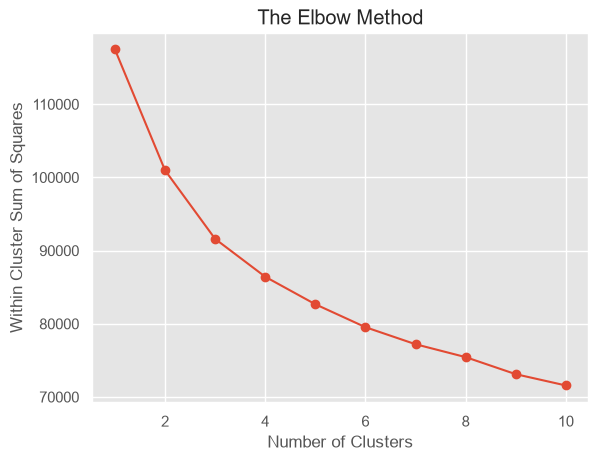

In [22]:
plt.plot(range(1,11), wcss, 'o-')
plt.title("The Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Within Cluster Sum of Squares")
plt.show()

## Training the K-means model on the dataset

In [23]:
kmeans = KMeans(n_clusters = 2, init='k-means++', random_state= 42)
kmeans_3 = KMeans(n_clusters = 3, init='k-means++', random_state= 42)

y_kmeans = kmeans.fit_predict(X_train)
y_kmeans3 = kmeans_3.fit_predict(X_train)

In [24]:
print(y_kmeans)

[0 1 1 ... 0 1 0]


In [25]:
# Silhouette scores on a random sample of 10,000 rows (the full computation compares every pair of rows)
sil_score = silhouette_score(X_train, kmeans.labels_, sample_size=10000, random_state=42)
sil_score_3 = silhouette_score(X_train, kmeans_3.labels_, sample_size=10000, random_state=42)
print(f"Silhouette Score for 2 clusters: {sil_score}")
print(f"Silhouette Score for 3 clusters: {sil_score_3}")
sample = np.random.default_rng(42).choice(len(X_train), 10000, replace=False)

Silhouette Score for 2 clusters: 0.13740161238452028
Silhouette Score for 3 clusters: 0.12751714744783105


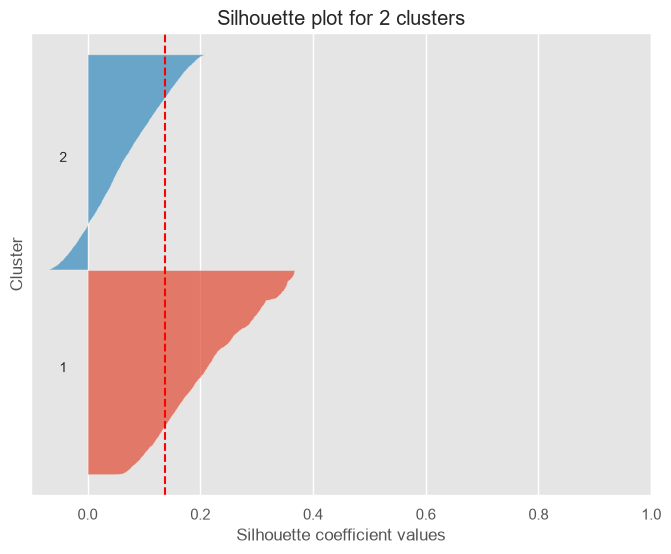

In [26]:
silhouette_vals = silhouette_samples(X_train.iloc[sample], y_kmeans[sample])

fig, ax = plt.subplots(figsize=(8, 6))

y_lower = 10
n_clusters = 2
for i in range(n_clusters):
    ith_cluster_silhouette_vals = silhouette_vals[y_kmeans[sample] == i]
    ith_cluster_silhouette_vals.sort()

    size_cluster_i = ith_cluster_silhouette_vals.shape[0]
    y_upper = y_lower + size_cluster_i

    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0, ith_cluster_silhouette_vals,
                     alpha=0.7)

    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i + 1))

    y_lower = y_upper + 10

ax.axvline(x=sil_score, color="red", linestyle="--")

ax.set_xlabel("Silhouette coefficient values")
ax.set_ylabel("Cluster")

ax.set_title(f"Silhouette plot for {n_clusters} clusters")
ax.set_yticks([])
ax.set_xlim([-0.1, 1])

plt.show()

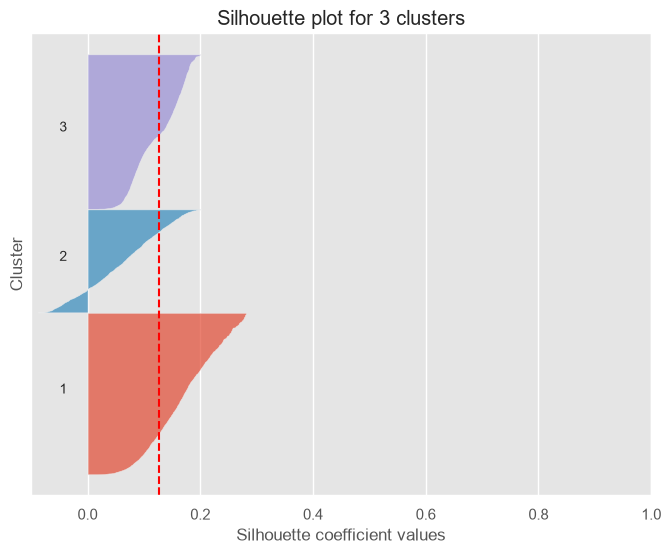

In [27]:
silhouette_vals = silhouette_samples(X_train.iloc[sample], y_kmeans3[sample])

fig, ax = plt.subplots(figsize=(8, 6))

y_lower = 10
n_clusters = 3
for i in range(n_clusters):
    ith_cluster_silhouette_vals = silhouette_vals[y_kmeans3[sample] == i]
    ith_cluster_silhouette_vals.sort()

    size_cluster_i = ith_cluster_silhouette_vals.shape[0]
    y_upper = y_lower + size_cluster_i

    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0, ith_cluster_silhouette_vals,
                     alpha=0.7)

    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i + 1))

    y_lower = y_upper + 10

ax.axvline(x=sil_score_3, color="red", linestyle="--")

ax.set_xlabel("Silhouette coefficient values")
ax.set_ylabel("Cluster")

ax.set_title(f"Silhouette plot for {n_clusters} clusters")
ax.set_yticks([])
ax.set_xlim([-0.1, 1])

plt.show()

# Classification: Logistic Regression

In [28]:
classifier_lr = LogisticRegression(random_state = 0)
classifier_lr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [29]:
print(classifier_lr.predict(X_test.iloc[4].values.reshape(1,-1)))

[1.]


In [30]:
y_pred = classifier_lr.predict(X_test)

# Setting print options
np.set_printoptions(precision=2)

# Ensure y_test and y_pred are NumPy arrays
y_test_array = y_test.values if isinstance(y_test, pd.DataFrame) else y_test
y_pred_array = y_pred

# Use np.column_stack to stack y_pred and y_test as columns
result = np.column_stack((y_pred_array, y_test_array))

# Print the result
print(result)

[[0. 0.]
 [1. 1.]
 [0. 0.]
 ...
 [0. 0.]
 [0. 0.]
 [1. 1.]]


In [31]:
cm_lr = confusion_matrix(y_test, y_pred)
print(cm_lr)

[[7805 2876]
 [2447 8080]]


**75% of the test set is classified correctly.**

In [32]:
evaluate_metrics("Logistic regression", y_test, y_pred)

{'accuracy': 0.7490098076197661,
 'recall': 0.7675501092428992,
 'precision': 0.737495436290617,
 'f1score': 0.7522226877065586}

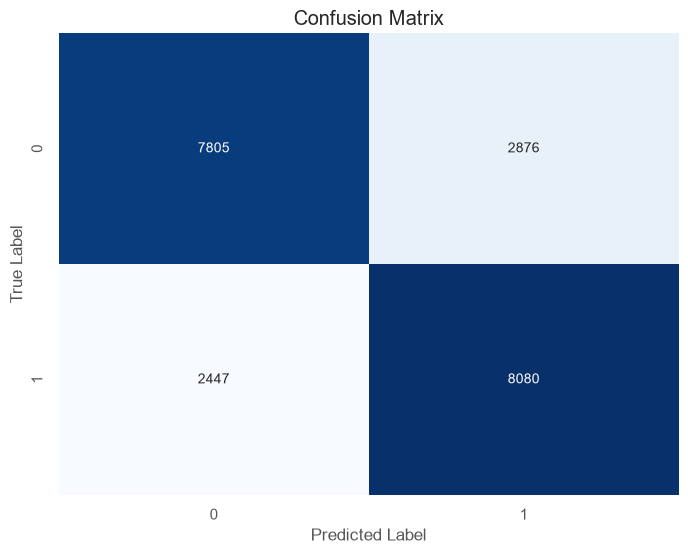

In [33]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

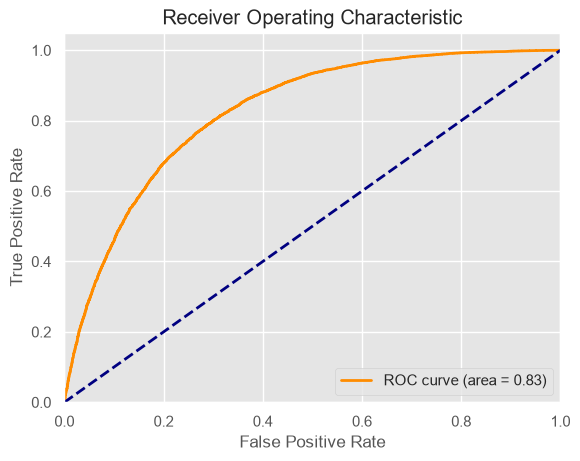

In [34]:
y_pred_proba = classifier_lr.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure()
plt.plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_lr)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

### Feature Importance

                 Feature  Importance
3                    BMI    6.406917
11               GenHlth    2.430593
16                   Age    1.845903
2              CholCheck    1.362750
0                 HighBP    0.745994
1               HighChol    0.578768
6   HeartDiseaseorAttack    0.242550
15                   Sex    0.219290
14              DiffWalk    0.187219
5                 Stroke    0.182659
4                 Smoker    0.022679
8                 Fruits   -0.030975
7           PhysActivity   -0.041142
9                Veggies   -0.074644
12              MentHlth   -0.081822
13              PhysHlth   -0.250950
10     HvyAlcoholConsump   -0.844833


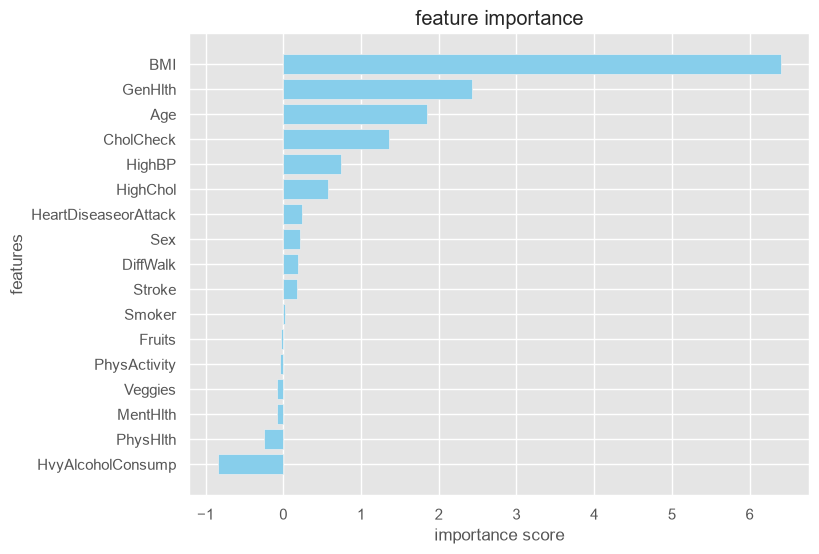

In [35]:
feature_importance = classifier_lr.coef_[0]


feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importance
})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print(feature_importance_df)

plt.figure(figsize=(8, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.xlabel('importance score')
plt.ylabel('features')
plt.title('feature importance')
plt.gca().invert_yaxis()
plt.show()

# Classification: K-NN

In [36]:
classifier_knn = KNeighborsClassifier(n_neighbors = 20, metric = 'manhattan', p = 2)
classifier_knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'


In [37]:
print(classifier_knn.predict(X_test.iloc[4].values.reshape(1,-1)))

[1.]


In [38]:
y_pred = classifier_knn.predict(X_test)
np.set_printoptions(precision=2)
y_test_array = y_test.values if isinstance(y_test, pd.DataFrame) else y_test
y_pred_array = y_pred
result = np.column_stack((y_pred_array, y_test_array))
print(result)

[[0. 0.]
 [1. 1.]
 [0. 0.]
 ...
 [0. 0.]
 [1. 0.]
 [1. 1.]]


In [39]:
cm_knn = confusion_matrix(y_test, y_pred)
print(cm_knn)
print("K-NN accuracy score:", accuracy_score(y_test, y_pred))

[[7551 3130]
 [2549 7978]]
K-NN accuracy score: 0.7322236891738967


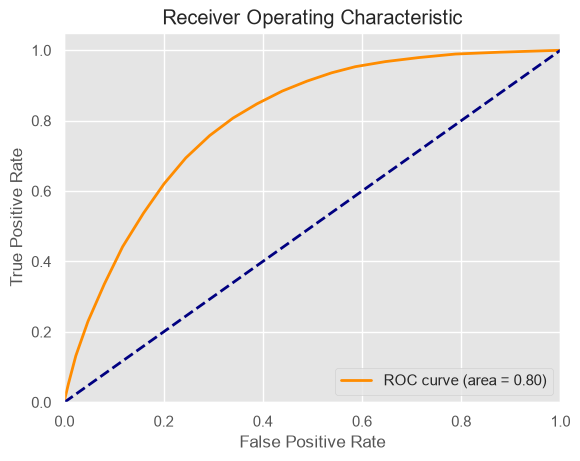

In [40]:
y_pred_proba = classifier_knn.predict_proba(X_test)[:, 1]
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_proba)
roc_auc_knn = auc(fpr_knn, tpr_knn)

plt.figure()
plt.plot(fpr_knn, tpr_knn, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc_knn)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [41]:
evaluate_metrics("K-NN", y_test, y_pred)

{'accuracy': 0.7322236891738967,
 'recall': 0.7578607390519616,
 'precision': 0.7182211019085344,
 'f1score': 0.7375086665125953}

# Classification: Decision Tree

In [42]:
classifier_dt = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
classifier_dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [43]:
print(classifier_dt.predict(X_test.iloc[4].values.reshape(1,-1)))

[0.]


In [44]:
y_pred = classifier_dt.predict(X_test)

np.set_printoptions(precision=2)

y_test_array = y_test.values if isinstance(y_test, pd.DataFrame) else y_test
y_pred_array = y_pred

result = np.column_stack((y_pred_array, y_test_array))

print(result)

[[0. 0.]
 [1. 1.]
 [0. 0.]
 ...
 [0. 0.]
 [0. 0.]
 [1. 1.]]


In [45]:
cm_dt = confusion_matrix(y_test, y_pred)
print(cm_dt)
print("Decision Tree accuracy score:", accuracy_score(y_test, y_pred))

[[7260 3421]
 [3741 6786]]
Decision Tree accuracy score: 0.6622972463221426


In [46]:
evaluate_metrics("Decision Tree",y_test, y_pred)

{'accuracy': 0.6622972463221426,
 'recall': 0.6446280991735537,
 'precision': 0.6648378563730774,
 'f1score': 0.654577023246841}

# Classification: Random Forest

In [47]:
classifier_rf = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 0)
classifier_rf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boots

In [48]:
y_pred = classifier_rf.predict(X_test)

In [49]:
cm_rf = confusion_matrix(y_test, y_pred)
print(cm_rf)
print("Random Forest Classifier accuracy score:", accuracy_score(y_test, y_pred))

[[7394 3287]
 [2572 7955]]
Random Forest Classifier accuracy score: 0.7237363259147491


In [50]:
evaluate_metrics("Random Forest",y_test, y_pred)

{'accuracy': 0.7237363259147491,
 'recall': 0.7556758810677306,
 'precision': 0.7076143035047144,
 'f1score': 0.7308558041251321}

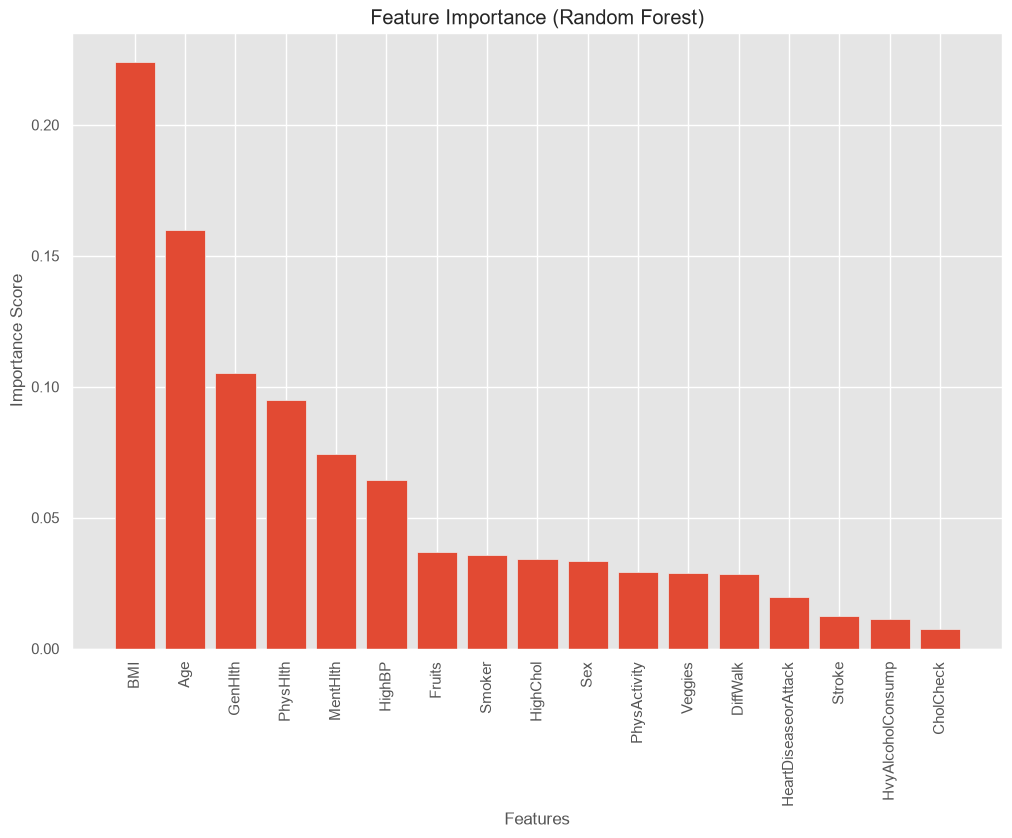

In [51]:
importances = classifier_rf.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X_train.columns

plt.figure(figsize=(12, 8))
plt.title("Feature Importance (Random Forest)")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), feature_names[indices], rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.show()

# Gradient Boosting Classifier

In [52]:
gbc = GradientBoostingClassifier()
gbc.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [53]:
y_pred = gbc.predict(X_test)

In [54]:
evaluate_metrics("Gradient Boosting Classifier",y_test, y_pred)

{'accuracy': 0.7554696341003395,
 'recall': 0.7959532630379025,
 'precision': 0.7339055793991416,
 'f1score': 0.7636711629602625}

# Neural Network

We build the neural network using Keras, a deep learning library in Python. Our network will have two layers and an output layer:
- First Hidden Layer: A dense (fully connected) layer with 6 units (neurons) and a ReLU activation function is added. This layer also acts as the input layer since it is the first layer of the model.
- Second Hidden Layer: Another dense layer with 6 units and a ReLU activation function is added. This provides another layer of abstraction for learning.
- Output Layer: A dense layer with 1 unit and a sigmoid activation function is added. The sigmoid function is used here because this is a binary classification problem, and the output will be a probability (a value between 0 and 1).

## Build the network

In [55]:
keras.utils.set_random_seed(42)  # reproducible weights and shuffling

#initializing the neural network
ann = models.Sequential()
#Input layer and the first hidden layer
ann.add(layers.Dense(units=6, activation='relu'))
#Second hidden layer
ann.add(layers.Dense(units=6, activation='relu'))
#Output layer
ann.add(layers.Dense(units=1, activation='sigmoid'))
ann.compile(optimizer ='adam', loss = 'binary_crossentropy',
            metrics = ['accuracy', keras.metrics.Recall(name='recall'), keras.metrics.Precision(name='precision')])

## Train the network

- Optimizer: The Adam optimizer is chosen, which is an efficient and widely used optimization algorithm in deep learning.
- Loss Function: The binary cross-entropy loss function is specified because this is a binary classification problem.
- Metrics: accuracy, recall and precision are monitored during training.

- Input Data: The model is trained using the training data (X_train for features and y_train for labels).
- Batch Size: The batch size is set to 32, meaning that the model will process 32 samples at a time before updating the weights.
- Epochs: The model is trained for 25 epochs, meaning that the entire training dataset is passed through the model 25 times.

In [56]:
ann.fit(X_train, y_train, batch_size = 32, epochs = 25, verbose = 2)

Epoch 1/25


1547/1547 - 2s - 1ms/step - accuracy: 0.6743 - loss: 0.5900 - precision: 0.6565 - recall: 0.7353


Epoch 2/25


1547/1547 - 1s - 550us/step - accuracy: 0.7342 - loss: 0.5356 - precision: 0.7165 - recall: 0.7777


Epoch 3/25


1547/1547 - 1s - 536us/step - accuracy: 0.7409 - loss: 0.5242 - precision: 0.7213 - recall: 0.7879


... (40 outputs left out)

Epoch 24/25


1547/1547 - 1s - 554us/step - accuracy: 0.7502 - loss: 0.5072 - precision: 0.7270 - recall: 0.8039


Epoch 25/25


1547/1547 - 1s - 545us/step - accuracy: 0.7503 - loss: 0.5073 - precision: 0.7261 - recall: 0.8063


In [57]:
y_pred = (ann.predict(X_test, verbose=0).ravel() > 0.5).astype(int)
evaluate_metrics("Neural network", y_test, y_pred)

{'accuracy': 0.7530648811769144,
 'recall': 0.7937684050536715,
 'precision': 0.7315706531255471,
 'f1score': 0.7614014305890929}

# Metrics Comparison

- Gradient Boosting performs best overall, with the highest accuracy (0.755), recall (0.796) and F1 score (0.764).
- The neural network is a close second on every metric (accuracy 0.753, F1 0.761).
- Logistic Regression has the highest precision (0.737) and is within one point of the best accuracy, while staying fully interpretable.
- A single Decision Tree overfits and performs worst; averaging 100 trees in the Random Forest recovers about 6 points of accuracy.

In [58]:
metrics_df = pd.DataFrame.from_dict(all_metrics, orient='index').round(3)
metrics_df

,accuracy,recall,precision,f1score
Logistic regression,0.749,0.768,0.737,0.752
K-NN,0.732,0.758,0.718,0.738
Decision Tree,0.662,0.645,0.665,0.655
Random Forest,0.724,0.756,0.708,0.731
Gradient Boosting Classifier,0.755,0.796,0.734,0.764
Neural network,0.753,0.794,0.732,0.761
